## Pegasus Evaluation: Fine-Tuning

Section C.1. Setup, methods and metrics: `2_B1_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`. The deployed plan
and its testbed runs: C.2, `2_C2_optimization.ipynb`.

In [1]:
# Data source of C.1: "real", the testbed runs of a plan that C.2 deployed (statics/results_milos_v2/c2/v2, slo_planning.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
print(f"{data_source} data, {len(seeds)} seeds")

real data, 3 seeds


### C.1 Fine-Tuning Bounds with End-to-End Samples

The question: after $n$ end-to-end samples of a composition, how well does each method predict the p95 latency of a
deployment of that composition and of the configurations around it? A *run* is one measurement of a few hundred
requests at one configuration and arrival rate; an *end-to-end sample* is a run of the composition whose end-to-end
latencies and latencies per service are known.

- **Composition and samples:** V1 (detector → transformer → compressor), the chain of B.1 `C1_CHAIN`. Its held-out runs
  of B.1 (configurations drawn at random, up to `MAX_WORKERS` workers per service, every run at half the capacity of
  its busiest service) and a copy of one of them, drawn at random per seed, are the pool of samples, `c1_sizes[-1]`
  runs. Per seed, the samples are the first $n$ of the pool in a random order (one value of `c1_sizes` per setting;
  $n = 0$ is the bound without fine-tuning).
- **Test set:** the deployment of C.2 that uses V1, `C1_SCENARIO` (S-V-3 forensic detail), and its neighborhood, all
  at the arrival rate of the scenario: the deployed plan (`C2_RESULTS`, its 50 runs pooled into one test point) and one
  run of every neighboring configuration (`NEIGHBORHOOD_RESULTS`: other data qualities and other workers per service).
  None of them is a sample. Runs that the testbed marked invalid (a service overloaded so that its queue kept
  growing, or refusing requests) are left out, as in B.1: their latencies do not settle, so they have no p95 to
  compare with.
- **Ground truth:** per test point, the measured p95 and the lower edge of its confidence interval
  (`measured_quantiles`, batch means, as in B.1). A method *covers* a test point if its prediction is not below that
  lower edge; it *holds* if it covers at least a share $\gamma$ = `confidence` of the test points under every seed.
- **Pegasus (pretrained):** the bound of B.1 with its load-aware models (`same_information_methods`): per seed the same
  training runs and GPs as B.1, evaluated at the samples and at the test points. The bound is multiplied by the
  split-conformal factor of `pegasus/finetuning.py`, the $\lceil (n+1)\gamma \rceil$-th smallest ratio measured p95 ÷
  bound over the samples. That rank exists only for $n \ge \gamma / (1 - \gamma)$ (`c1_calibrated`); with fewer
  samples Pegasus keeps the bound of B.1. *Assumption broken here:* the conformal guarantee needs samples that are
  exchangeable with the test points, but the samples are random configurations at half the capacity, and the test
  points one region at the rate of the scenario. Whether the factor transfers is what C.1 measures, not a guarantee.
- **Pegasus (blank):** the same bound without the pretraining on the benchmarks, on the same $n$ samples as
  the baselines. Its GPs are trained on the first $\min(n, m)$ samples, $m$ = `C1_GP_RUNS`; a sample gives every
  service one training run: its mean execution time (mean processing time plus the handling overhead of the run) and
  its spread ((p95 − median) ÷ 1.645 of the processing time), as the training runs of B.1 (`training_pool`), with the
  inputs of the load-aware models. The samples after the first $m$ calibrate the bound like the samples of Pegasus
  (pretrained), because split-conformal calibration needs samples that the models did not train on: up to $n = m$ every
  sample trains and the bound is not calibrated; beyond, the GPs stay as they are and the $n - m$ later samples
  calibrate it (from `c1_calibrated` of them on). It has no point at $n = 0$. At the largest $n$ the copy in the pool
  can be both a training and a calibration sample.
- **Baselines trained on the samples** (`pegasus/finetuning.py`, as in the earlier C.1): *Quantile Sum* (one GP per
  service of the p95 of its latency inside the chain, waiting plus processing, the predictions summed) and
  *Fluxion-style* (one GP per position, fed by the predicted quantiles of the position before it). Their inputs are
  those of the load-aware models: per service its knobs, workers and log10 of the arrival rate. Both add the handover
  between the services, $(K-1)\,h$ with $K$ the number of services and $h$ the handover per hop of the platform
  (`platform_handover`), which the bound contains and no service latency does. Neither is a bound.
- **Overloaded test points:** where the models expect a service to be overloaded, Pegasus gives no finite bound. These
  test points count in the coverage (an infinite bound covers) but not in the tightness, which is the median over the
  other test points of the seed.

Figure: `figures/tsc/experimental-results/c1_finetuning_deployment`: the tightness (prediction ÷ measured p95, the
median over the test points with a finite bound of Pegasus) over the number of samples $n$; the line is the median over
the seeds and the band the range over the seeds; a filled marker means that the method holds under every seed, a hollow
one that it does not.

In [2]:
if data_source != "real":
    print("C.1 skipped: real data only (the testbed runs of a plan of C.2)")
else:
    # C.1: samples from the B.1 runs of V1, the GPs of B.1, test points at the deployment of S-V-3. This cell imports what it needs itself.
    import json
    from dataclasses import replace
    import slo_planning as sp
    from pegasus import real_data
    from pegasus.data import load_aware
    from pegasus.evaluation import fit_services, hop_time, pegasus_bound
    from pegasus.finetuning import COLORS as C1_COLORS, FLUXION, QUANTILE_SUM, finetuned_bound, fluxion_style, quantile_sum
    from pegasus.real_data import NOT_CONFIGURATION, POOL_COLUMNS

    C1_CHAIN = f"b1-vision-1-single+b1u-max{MAX_WORKERS}"   # V1 in B.1: its held-out runs are the pool of samples
    C1_SCENARIO = "S-V-3 forensic detail"                    # the deployment of V1 in C.2 (2_C2_optimization.ipynb) that is tested
    # the two versions of Pegasus in C.1: pretrained on the benchmarks (PROPOSED of B.1, renamed here, in its color) and blank (trained on
    # the end-to-end samples alone)
    PRETRAINED, BLANK = "Pegasus (pretrained)", "Pegasus (blank)"
    METHOD_COLORS[PRETRAINED] = METHOD_COLORS[PROPOSED]
    METHOD_COLORS.update(C1_COLORS)   # colors of the two baselines
    # the smallest number of samples at which the conformal rank ceil((n + 1) * confidence) is at most n; below it Pegasus
    # keeps the bound of B.1 (calibration_factor)
    c1_calibrated = int(np.ceil(confidence / (1 - confidence) - 1e-9))
    # number of samples; 0 is the bound of B.1 without fine-tuning
    c1_sizes = [0, 25, 50, 75, 100, 125, 150]
    C1_GP_RUNS = 75   # samples that train the GPs of Pegasus (blank); the samples after them calibrate its bound
    METHOD_COLORS[BLANK] = "tab:olive"
    # the training target of every service in every held-out run of B.1, as training_pool defines it for a training run: the mean
    # execution time (s; mean processing time plus the handling overhead of the run) and the spread (s; (p95 - median) / NORMAL_P95 of the
    # processing time); nan where the run has no measurable handling overhead
    c1_runs = real_data.combined_runs(C1_CHAIN)   # (experiment, run_id) of every held-out run, in the order of real_chain_data
    c1_run_targets = {}
    for node in real_data.chain_path(C1_CHAIN)[0]:
        node_rows = {experiment: real_data.run_table(experiment)[real_data.run_table(experiment)["node"] == node].set_index("run_id")
                     for experiment in dict.fromkeys(experiment for experiment, _ in c1_runs)}
        statistics = pd.concat([node_rows[experiment].loc[[run_id]] for experiment, run_id in c1_runs])
        overhead = np.array([real_data.handling_overhead(experiment, run_id, node) for experiment, run_id in c1_runs])
        c1_run_targets[node] = (statistics["processing_mean_ms"].to_numpy() / 1e3 + overhead,
                                np.maximum((statistics["processing_p95_ms"] - statistics["processing_p50_ms"]).to_numpy() / real_data.NORMAL_P95 / 1e3, 1e-6))

    deployed = pd.read_csv(sp.DEPLOYED_PLANS)
    plan = deployed[deployed["scenario"] == C1_SCENARIO].iloc[0]   # the deployed plan: knobs, rate, predicted bound of C.2
    assert plan["experiment"] == real_data.combined_chain(C1_CHAIN)[1], f"{C1_SCENARIO} does not deploy the composition of {C1_CHAIN}"
    deployment, neighborhood = sp.c2_runs(plan), sp.c2_runs(plan, neighborhood=True)
    assert all(k == json.loads(plan["knobs"]) and r == plan["arrival_rate"] for k, r in zip(deployment["knobs"], deployment["rate"])), (
        f"{C1_SCENARIO}: a run of the deployment does not have the configuration of the plan")
    # the test points: the plan (its runs pooled) and every neighbor, with configuration, arrival rate (items/s) and measured p95 (s)
    c1_test_knobs = [deployment["knobs"][0]] + neighborhood["knobs"]
    c1_test_rates = np.array([deployment["rate"][0]] + neighborhood["rate"], dtype=float)
    c1_labels = ["deployed plan"] + [f"q = {k['shared.data_quality']}, workers " + "/".join(str(k[f"{node}.parallelism"]) for node in deployment["path"])
                                     for k in neighborhood["knobs"]]
    c1_measured, c1_measured_low = real_data.measured_quantiles([np.concatenate(deployment["latencies"]) / 1e3]
                                                                + [latency / 1e3 for latency in neighborhood["latencies"]], 1 - alpha, coverage_check)

    def compute():
        results = {}   # (size, seed) -> name -> (group, prediction per test point in s)
        with warnings.catch_warnings():
            # the GPs of the two baselines are fitted on few samples, and scikit-learn warns where their hyperparameters end at their bounds
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s in seeds:
                # the data of B.1 for V1 under this seed: its training runs, its held-out runs (the pool of samples) and their ground truth
                data = load_chain_data("real", experiment=C1_CHAIN, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s],
                                       n_train=N_TRAIN, training_campaign=WORKER_TRAINING)
                pool = len(data.measured)
                assert pool == len(c1_runs), "the held-out runs differ from combined_runs"
                # the pool of samples, as rows of the held-out runs: every held-out run and a copy of one of them, drawn at random, so that it
                # holds c1_sizes[-1] runs
                pool_rows = np.append(np.arange(pool), np.random.default_rng([seed, s, 101]).integers(pool))
                assert len(pool_rows) == c1_sizes[-1], f"the pool holds {len(pool_rows)} runs, not the largest number of samples"
                # the test points appended to the held-out runs, in the inputs of real_chain_data: per node its knobs in the column order of
                # its training pool (without POOL_COLUMNS and NOT_CONFIGURATION), and log10 of the arrival rate
                rates = np.concatenate([data.workload["rate"], c1_test_rates])
                x_test = {}
                for node in data.path:
                    names = [column for column in real_data.training_pool(real_data.chain_path(C1_CHAIN)[1][node], campaign=WORKER_TRAINING).columns
                             if column not in POOL_COLUMNS and column not in NOT_CONFIGURATION]
                    rows = [[k["shared.data_quality"] if name == "data_quality" else k[f"{node}.{name}"] for name in names] for k in c1_test_knobs]
                    x_test[node] = np.vstack([data.x_test[node], np.array(rows, dtype=float)])
                both = replace(data, x_test=x_test, x_test_load={node: np.column_stack([x, np.log10(rates)]) for node, x in x_test.items()},
                               workload={**data.workload, "rate": rates})
                # Pegasus with the load-aware models of B.1 (same_information_methods): the GPs are fitted on the training runs of this seed
                # (read from the model cache, as B.1 fitted them) and give the bound at the held-out runs and at the test points
                view = load_aware(both)
                bound = pegasus_bound(both, fit_services(view, view.x_train, both.y_train, model_seed=seed + s, confidence=confidence,
                                                         with_dnn=False), alpha)
                test = np.arange(pool, pool + len(c1_test_knobs))
                # the order in which the runs of the pool become samples (rows of the held-out runs; the copy is a row twice)
                order = pool_rows[np.random.default_rng([seed, s, 100]).permutation(len(pool_rows))]
                for size in c1_sizes:
                    samples = order[:size]
                    results[(size, s)] = {PRETRAINED: ("proposed", finetuned_bound(bound, data.measured, samples, test, miscoverage=1 - confidence))}
                    if size > 0:
                        for name, method in ((QUANTILE_SUM, quantile_sum), (FLUXION, fluxion_style)):
                            results[(size, s)][name] = ("baseline", method(both, samples, test, alpha) + hop_time(both))
                        # Pegasus (blank): every service trained on the first C1_GP_RUNS samples alone (a sample without a measurable
                        # handling overhead of the service is left out for that service), in the inputs of the load-aware models; its bound at
                        # every held-out run and test point, calibrated with the samples after them (finetuned_bound; none up to C1_GP_RUNS)
                        training, calibration = samples[:C1_GP_RUNS], samples[C1_GP_RUNS:]
                        used = {node: training[np.isfinite(c1_run_targets[node][0][training])] for node in both.path}
                        own = replace(both, x_train_load={node: both.x_test_load[node][used[node]] for node in both.path},
                                      y_train={node: c1_run_targets[node][0][used[node]] for node in both.path},
                                      y_train_spread={node: c1_run_targets[node][1][used[node]] for node in both.path})
                        own_view = load_aware(own)
                        own_bound = pegasus_bound(own, fit_services(own_view, own_view.x_train, own.y_train, model_seed=seed + s, confidence=confidence,
                                                                    with_dnn=False), alpha)
                        results[(size, s)][BLANK] = ("proposed", finetuned_bound(own_bound, data.measured, calibration, test,
                                                                                          miscoverage=1 - confidence))
        return dict(c1_results=results, c1_pool=pool)

    # the scenario, the sample sizes and the names of the versions of Pegasus (keys of the results) enter the key; the runs of C.2 do not
    # (they are fixed measurements)
    globals().update(cached("c1_finetuning_deployment", data_source, compute, inputs=dict(c1_sizes=c1_sizes, chain=C1_CHAIN, scenario=C1_SCENARIO, names=(PRETRAINED, BLANK),
                                                                                      gp_runs=C1_GP_RUNS)))
    c1_truth = {key: (c1_measured, c1_measured_low) for key in c1_results}
    # per seed, the test points at which the models of B.1 expect a service to be overloaded (no finite bound without samples)
    c1_overloaded = {s: ~np.isfinite(c1_results[(0, s)][PRETRAINED][1]) for s in seeds}
    # coverage and holds over all test points; tightness over the test points with a finite bound (markdown above)
    c1_statistics = sweep_statistics(c1_results, c1_truth, c1_sizes, seeds, confidence)
    stable = sweep_statistics({(size, s): {name: (group, latency[~c1_overloaded[s]]) for name, (group, latency) in methods.items()}
                               for (size, s), methods in c1_results.items()},
                              {(size, s): (m[~c1_overloaded[s]], low[~c1_overloaded[s]]) for (size, s), (m, low) in c1_truth.items()},
                              c1_sizes, seeds, confidence)
    for name in c1_statistics:
        c1_statistics[name]["tightness"] = stable[name]["tightness"]
    print(f"V1 ({' → '.join(deployment['path'])}): {c1_pool} held-out runs of B.1 and a copy of one of them as the pool of samples "
          f"({BLANK}: GPs on the first {C1_GP_RUNS}, calibration with the later ones); test points: the deployed plan of "
          f"{C1_SCENARIO} ({len(deployment['latencies'])} runs pooled) and {len(neighborhood['latencies'])} neighbors at "
          f"{plan['arrival_rate']:g} items/s; {len(seeds)} seeds; fine-tuned from n = {c1_calibrated}")
    print(f"bound of the plan with the models of B.1 per seed: {', '.join(f'{1e3 * c1_results[(0, s)][PRETRAINED][1][0]:.0f}' for s in seeds)} ms "
          f"(C.2, its models: {plan['predicted_p95_ms']:.0f} ms); measured p95 of the plan {1e3 * c1_measured[0]:.0f} ms; "
          f"test points without a finite bound per seed: {', '.join(str(c1_overloaded[s].sum()) for s in seeds)}")

c1_finetuning_deployment: results loaded from cache\evaluation\c1_finetuning_deployment_real+b1+b1u-max4_b6510b9c48d513a8.joblib
V1 (detector → transformer → compressor): 149 held-out runs of B.1 and a copy of one of them as the pool of samples (Pegasus (blank): GPs on the first 75, calibration with the later ones); test points: the deployed plan of S-V-3 forensic detail (50 runs pooled) and 26 neighbors at 12 items/s; 3 seeds; fine-tuned from n = 19
bound of the plan with the models of B.1 per seed: 1203, 1362, 1194 ms (C.2, its models: 1265 ms); measured p95 of the plan 888 ms; test points without a finite bound per seed: 2, 6, 2


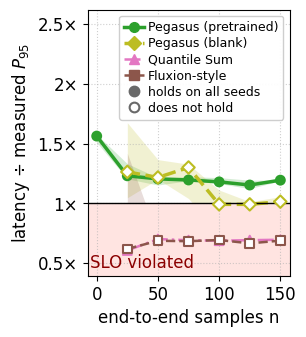

tightness (median over the seeds; ● holds, ○ does not):


,n = 0,n = 25,n = 50,n = 75,n = 100,n = 125,n = 150
Pegasus (pretrained),1.56× ●,1.23× ●,1.21× ●,1.20× ●,1.18× ●,1.15× ●,1.19× ●
Quantile Sum,–,0.61× ○,0.70× ○,0.69× ○,0.69× ○,0.69× ○,0.70× ○
Fluxion-style,–,0.62× ○,0.69× ○,0.68× ○,0.69× ○,0.67× ○,0.69× ○
Pegasus (blank),–,1.26× ○,1.22× ○,1.30× ○,0.99× ○,0.99× ○,1.01× ○


coverage of the test points (median over the seeds):


,n = 0,n = 25,n = 50,n = 75,n = 100,n = 125,n = 150
Pegasus (pretrained),100%,96%,96%,96%,96%,96%,96%
Quantile Sum,–,4%,11%,11%,11%,11%,11%
Fluxion-style,–,11%,11%,11%,11%,11%,11%
Pegasus (blank),–,96%,74%,81%,56%,56%,67%


the deployed plan of S-V-3 forensic detail: prediction (ms, median over the seeds) and ÷ its measured p95 (888 ms)


,n = 0,n = 25,n = 50,n = 75,n = 100,n = 125,n = 150
Pegasus (pretrained),1203 (1.35×),1041 (1.17×),929 (1.05×),948 (1.07×),940 (1.06×),919 (1.03×),947 (1.07×)
Quantile Sum,–,291 (0.33×),339 (0.38×),331 (0.37×),329 (0.37×),339 (0.38×),335 (0.38×)
Fluxion-style,–,274 (0.31×),317 (0.36×),329 (0.37×),331 (0.37×),290 (0.33×),298 (0.33×)
Pegasus (blank),–,847 (0.95×),723 (0.81×),787 (0.89×),598 (0.67×),598 (0.67×),614 (0.69×)


In [3]:
if data_source != "real":
    print("C.1 skipped: real data only")
else:
    from pegasus.finetuning import finetuning_figure
    # source: c1_statistics of the cell above
    # half the width of an evaluation figure; the legend in one column, because two columns are wider than its plot area
    finetuning_figure(c1_sizes, c1_statistics, p_label, output=Path("../../figures/tsc") / "c1_finetuning_deployment", half=True,
                      legend_options=dict(ncol=1, fontsize=9, handlelength=1.6, handletextpad=0.3, labelspacing=0.25,
                                          locations=("upper right",)),
                      styles={PRETRAINED: "o-", BLANK: "D--"}, xlabel="end-to-end samples n")
    print("tightness (median over the seeds; ● holds, ○ does not):")
    display(sweep_table(c1_sizes, c1_statistics, list(c1_statistics), lambda size: f"n = {size}"))
    print("coverage of the test points (median over the seeds):")
    display(pd.DataFrame({f"n = {size}": {name: f"{np.nanmedian(statistics['coverage'][i]):.0%}" if statistics["computed"][i] else "–"
                                          for name, statistics in c1_statistics.items()} for i, size in enumerate(c1_sizes)}))
    # the deployed plan alone: prediction of every method (median over the seeds) against its measured p95
    print(f"the deployed plan of {C1_SCENARIO}: prediction (ms, median over the seeds) and ÷ its measured p95 ({1e3 * c1_measured[0]:.0f} ms)")
    display(pd.DataFrame({f"n = {size}": {name: (lambda value: f"{1e3 * value:.0f} ({value / c1_measured[0]:.2f}×)" if np.isfinite(value) else "∞")(
                                              np.median([c1_results[(size, s)][name][1][0] for s in seeds]))
                                          for name in c1_statistics if name in c1_results[(size, seeds[0])]} for size in c1_sizes}).fillna("–"))